# Employee Attrition Prediction Models
**IBM HR Analytics – Classification (Attrition) + Optional Regression (Job Satisfaction)**

Pipeline: data loading → EDA → preprocessing → 4 classifiers (Logistic Regression, Decision Tree, Random Forest, XGBoost)
→ metrics (Accuracy, Precision, Recall, F1, ROC-AUC) → 5-fold cross-validation → hyper-parameter tuning → feature importance → regression task.

> **Data note:** if `data/WA_Fn-UseC_-HR-Employee-Attrition.csv` (the real IBM/Kaggle file) exists, it is used.
> Otherwise the notebook falls back to `data/synthetic_hr_attrition.csv`, a synthetic dataset with the identical schema.

In [1]:
import os, json, warnings, pathlib
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg") if os.environ.get("HEADLESS") else None
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)
warnings.filterwarnings("ignore")

try:
    from xgboost import XGBClassifier
    XGB_REAL = True
except ImportError:          # keeps the notebook runnable where xgboost is not installed
    XGB_REAL = False
XGB_LABEL = "XGBoost" if XGB_REAL else "XGBoost (fallback: sklearn HistGradientBoosting)"

SEED = 42
ROOT = pathlib.Path("..") if pathlib.Path("../data").exists() else pathlib.Path(".")
FIG = ROOT / "results" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
RES = ROOT / "results"
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / name, dpi=150, bbox_inches="tight"); plt.show()
print("XGBoost available:", XGB_REAL)

XGBoost available: False


## 1. Load data

In [1]:
real = ROOT / "data" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
synth = ROOT / "data" / "synthetic_hr_attrition.csv"
DATA_PATH = real if real.exists() else synth
DATA_SOURCE = "IBM HR Analytics (real)" if real.exists() else "synthetic stand-in (IBM schema)"
df = pd.read_csv(DATA_PATH)
print("Source:", DATA_SOURCE, "|", DATA_PATH.name)
print("Shape:", df.shape, "| missing values:", int(df.isna().sum().sum()))
df.head()

Source: synthetic stand-in (IBM schema) | synthetic_hr_attrition.csv
Shape: (1470, 35) | missing values: 0


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,40,Yes,Travel_Rarely,720,Research & Development,16,2,Medical,1,1,3,Male,63,3,1,Manufacturing Director,4,Single,4622,7782,2,Y,Yes,11,3,2,80,0,4,4,3,3,2,1,1
1,28,Yes,Travel_Rarely,1162,Research & Development,16,2,Life Sciences,1,2,4,Male,94,1,2,Laboratory Technician,1,Single,9863,9750,2,Y,No,21,4,4,80,0,2,6,3,2,0,0,1
2,44,No,Travel_Rarely,204,Research & Development,7,4,Marketing,1,3,2,Male,97,3,4,Healthcare Representative,3,Single,15799,22289,1,Y,No,11,3,2,80,0,13,3,2,11,10,7,7
3,45,No,Travel_Rarely,322,Research & Development,12,4,Medical,1,4,3,Male,90,3,4,Research Director,2,Married,16215,20999,2,Y,No,15,3,4,80,0,16,4,2,9,9,5,3
4,19,No,Travel_Rarely,628,Sales,3,5,Medical,1,5,4,Male,89,3,3,Sales Representative,1,Single,12907,16034,2,Y,No,16,3,4,80,1,1,4,2,0,0,0,0


## 2. Exploratory data analysis

Attrition rate: 15.7%  ->  class imbalance (handled with class weights)


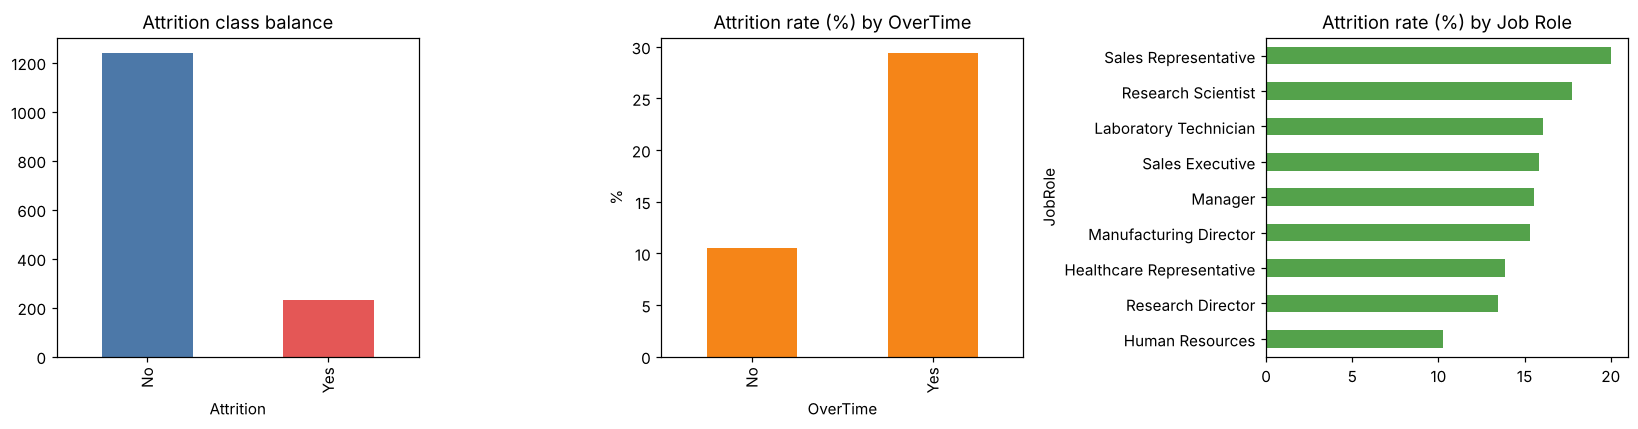

In [1]:
rate = (df.Attrition == "Yes").mean()
print(f"Attrition rate: {rate:.1%}  ->  class imbalance (handled with class weights)")
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.Attrition.value_counts().plot.bar(ax=ax[0], color=["#4c78a8", "#e45756"]); ax[0].set_title("Attrition class balance")
(df.assign(A=df.Attrition.eq("Yes")).groupby("OverTime").A.mean() * 100).plot.bar(ax=ax[1], color="#f58518")
ax[1].set_title("Attrition rate (%) by OverTime"); ax[1].set_ylabel("%")
(df.assign(A=df.Attrition.eq("Yes")).groupby("JobRole").A.mean().sort_values() * 100).plot.barh(ax=ax[2], color="#54a24b")
ax[2].set_title("Attrition rate (%) by Job Role")
savefig("01_eda_attrition.png")

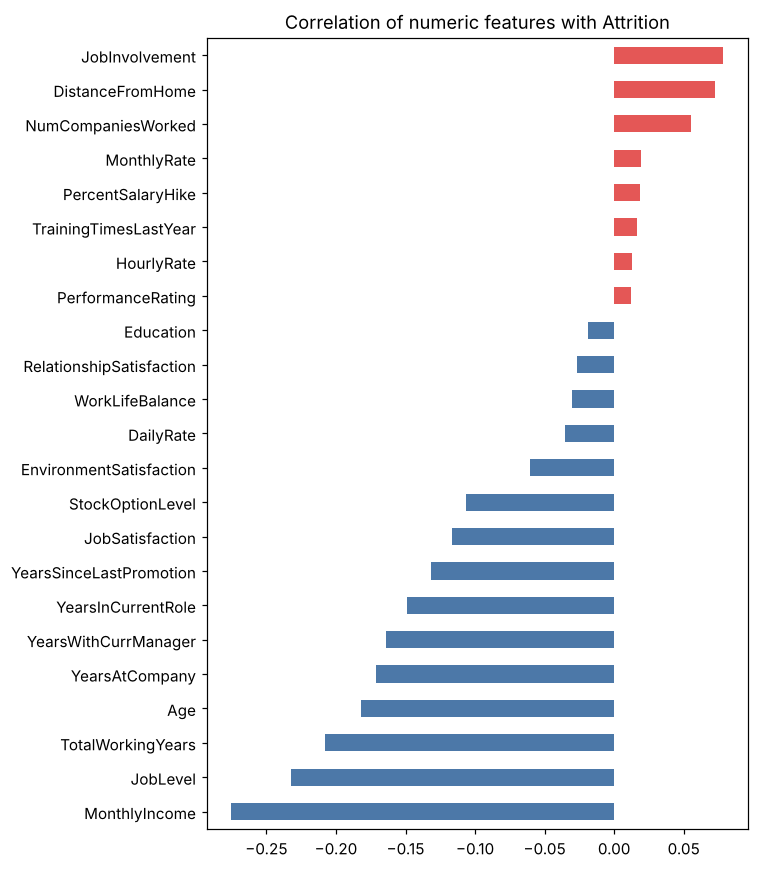

In [1]:
num_corr = df.assign(Attrition=df.Attrition.eq("Yes").astype(int)).select_dtypes("number").drop(
    columns=["EmployeeCount", "StandardHours", "EmployeeNumber"]).corr()["Attrition"].drop("Attrition").sort_values()
plt.figure(figsize=(7, 8)); num_corr.plot.barh(color=np.where(num_corr > 0, "#e45756", "#4c78a8"))
plt.title("Correlation of numeric features with Attrition"); savefig("02_correlation.png")

## 3. Preprocessing
* Drop constant / identifier columns (`EmployeeCount`, `Over18`, `StandardHours`, `EmployeeNumber`).
* Target: `Attrition` → 1 = left, 0 = stayed.
* Stratified 80/20 train/test split.
* Numeric → `StandardScaler`; categorical → `OneHotEncoder`. Everything sits in a `Pipeline`, so no information leaks from the test set.

In [1]:
DROP = ["EmployeeCount", "Over18", "StandardHours", "EmployeeNumber"]
y = df.Attrition.eq("Yes").astype(int)
X = df.drop(columns=DROP + ["Attrition"])
cat_cols = X.select_dtypes("object").columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "Test:", X_test.shape, "| positives train/test:", y_train.sum(), y_test.sum())

def make_pre():
    return ColumnTransformer([("num", StandardScaler(), num_cols),
                              ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)])
pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

Train: (1176, 30) Test: (294, 30) | positives train/test: 185 46


## 4. Baseline models

In [1]:
def build_models():
    m = {
        "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED),
        "Decision Tree": DecisionTreeClassifier(class_weight="balanced", max_depth=5, random_state=SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1),
    }
    if XGB_REAL:
        m[XGB_LABEL] = XGBClassifier(n_estimators=300, learning_rate=0.1, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                     scale_pos_weight=pos_weight, eval_metric="logloss", random_state=SEED, n_jobs=-1)
    else:
        m[XGB_LABEL] = HistGradientBoostingClassifier(max_depth=4, learning_rate=0.1, class_weight="balanced", random_state=SEED)
    return m

def metrics(model, Xt, yt):
    pred = model.predict(Xt); proba = model.predict_proba(Xt)[:, 1]
    return {"Accuracy": accuracy_score(yt, pred), "Precision": precision_score(yt, pred, zero_division=0),
            "Recall": recall_score(yt, pred), "F1": f1_score(yt, pred), "ROC-AUC": roc_auc_score(yt, proba)}

base = {n: Pipeline([("pre", make_pre()), ("clf", m)]).fit(X_train, y_train) for n, m in build_models().items()}
base_df = pd.DataFrame({n: metrics(p, X_test, y_test) for n, p in base.items()}).T.round(3)
base_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.735,0.314,0.587,0.409,0.771
Decision Tree,0.660,0.240,0.543,0.333,0.668
Random Forest,0.837,0.458,0.239,0.314,0.739
XGBoost (fallback: sklearn HistGradientBoosting),0.786,0.319,0.326,0.323,0.731


## 5. Cross-validation (5-fold, stratified, on the training set)

In [1]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
scoring = {"Accuracy": "accuracy", "Precision": "precision", "Recall": "recall", "F1": "f1", "ROC-AUC": "roc_auc"}
cv_rows = {}
for n, m in build_models().items():
    r = cross_validate(Pipeline([("pre", make_pre()), ("clf", m)]), X_train, y_train, cv=skf, scoring=scoring, n_jobs=-1)
    cv_rows[n] = {k: f"{r['test_'+k].mean():.3f} ± {r['test_'+k].std():.3f}" for k in scoring}
cv_df = pd.DataFrame(cv_rows).T
cv_df

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.748 ± 0.026,0.349 ± 0.044,0.697 ± 0.106,0.465 ± 0.062,0.816 ± 0.053
Decision Tree,0.698 ± 0.055,0.297 ± 0.042,0.632 ± 0.063,0.401 ± 0.034,0.697 ± 0.031
Random Forest,0.852 ± 0.010,0.545 ± 0.053,0.357 ± 0.096,0.426 ± 0.071,0.792 ± 0.035
XGBoost (fallback: sklearn HistGradientBoosting),0.820 ± 0.026,0.442 ± 0.067,0.541 ± 0.070,0.486 ± 0.068,0.769 ± 0.032


## 6. Hyper-parameter tuning (RandomizedSearchCV, 5-fold, scored on ROC-AUC)

In [1]:
if XGB_REAL:
    xgb_space = {"clf__n_estimators": [100, 200, 300, 500], "clf__max_depth": [2, 3, 4, 5, 6], "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
                 "clf__subsample": [0.6, 0.8, 1.0], "clf__colsample_bytree": [0.6, 0.8, 1.0], "clf__min_child_weight": [1, 3, 5]}
else:
    xgb_space = {"clf__max_iter": [100, 200, 300], "clf__max_depth": [2, 3, 4, 5, None], "clf__learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
                 "clf__min_samples_leaf": [10, 20, 40], "clf__l2_regularization": [0, 0.1, 1.0]}
spaces = {
    "Logistic Regression": {"clf__C": np.logspace(-3, 2, 20), "clf__penalty": ["l2"]},
    "Decision Tree": {"clf__max_depth": [2, 3, 4, 5, 6, 8, 10], "clf__min_samples_leaf": [1, 5, 10, 20, 40], "clf__criterion": ["gini", "entropy"]},
    "Random Forest": {"clf__n_estimators": [200, 300, 500], "clf__max_depth": [4, 6, 8, 12, None], "clf__min_samples_leaf": [1, 2, 5, 10],
                      "clf__max_features": ["sqrt", 0.3, 0.5]},
    XGB_LABEL: xgb_space,
}
tuned, best_params, best_cv = {}, {}, {}
for n, m in build_models().items():
    s = RandomizedSearchCV(Pipeline([("pre", make_pre()), ("clf", m)]), spaces[n], n_iter=20, scoring="roc_auc",
                           cv=skf, random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    tuned[n], best_cv[n] = s.best_estimator_, s.best_score_
    best_params[n] = {k.replace("clf__", ""): (v.item() if hasattr(v, "item") else v) for k, v in s.best_params_.items()}
    print(f"{n:55s} best CV ROC-AUC = {s.best_score_:.3f}  {best_params[n]}")

Logistic Regression                                     best CV ROC-AUC = 0.817  {'penalty': 'l2', 'C': 0.23357214690901212}
Decision Tree                                           best CV ROC-AUC = 0.724  {'min_samples_leaf': 40, 'max_depth': 4, 'criterion': 'entropy'}
Random Forest                                           best CV ROC-AUC = 0.795  {'n_estimators': 200, 'min_samples_leaf': 10, 'max_features': 'sqrt', 'max_depth': 6}
XGBoost (fallback: sklearn HistGradientBoosting)        best CV ROC-AUC = 0.804  {'min_samples_leaf': 20, 'max_iter': 100, 'max_depth': 2, 'learning_rate': 0.05, 'l2_regularization': 1.0}


## 7. Final evaluation on the held-out test set (tuned models)

In [1]:
tuned_df = pd.DataFrame({n: metrics(p, X_test, y_test) for n, p in tuned.items()}).T.round(3)
tuned_df["CV ROC-AUC (best)"] = pd.Series(best_cv).round(3)
cmp = pd.concat({"Baseline": base_df, "Tuned": tuned_df.drop(columns="CV ROC-AUC (best)")}, axis=1)
display(tuned_df) if "display" in globals() else print(tuned_df)

,Accuracy,Precision,Recall,F1,ROC-AUC,CV ROC-AUC (best)
Logistic Regression,0.745,0.325,0.587,0.419,0.776,0.817
Decision Tree,0.684,0.272,0.609,0.376,0.688,0.724
Random Forest,0.786,0.369,0.522,0.432,0.764,0.795
XGBoost (fallback: sklearn HistGradientBoosting),0.748,0.325,0.565,0.413,0.754,0.804


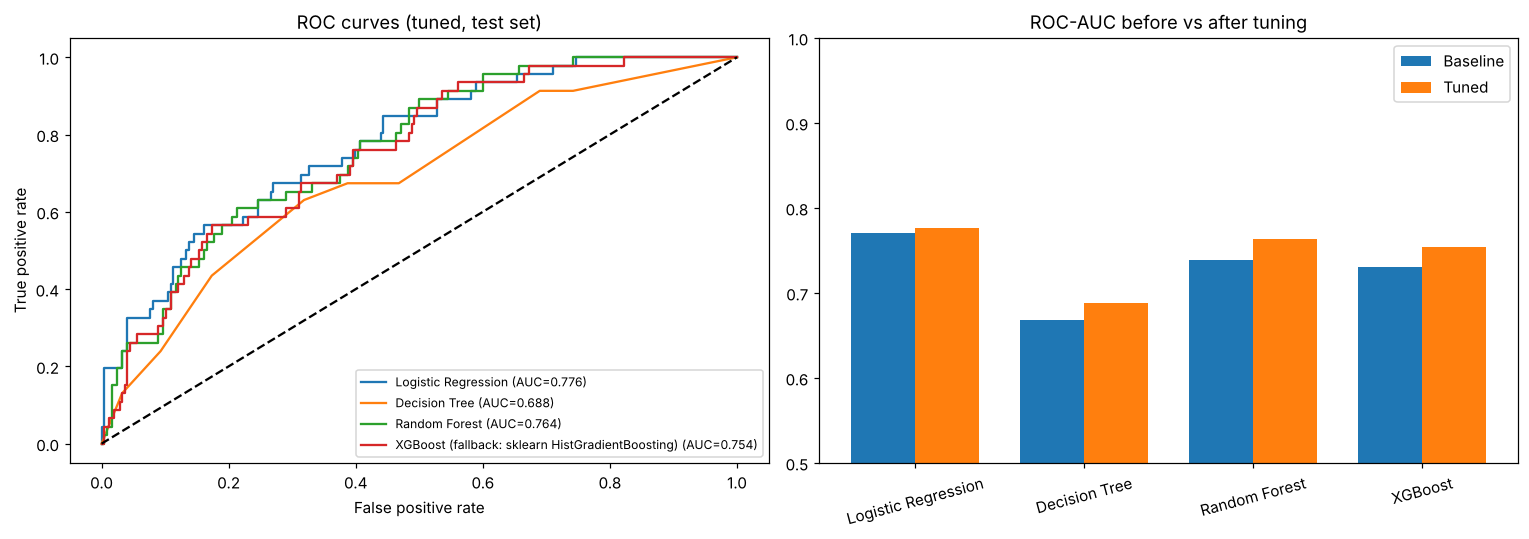

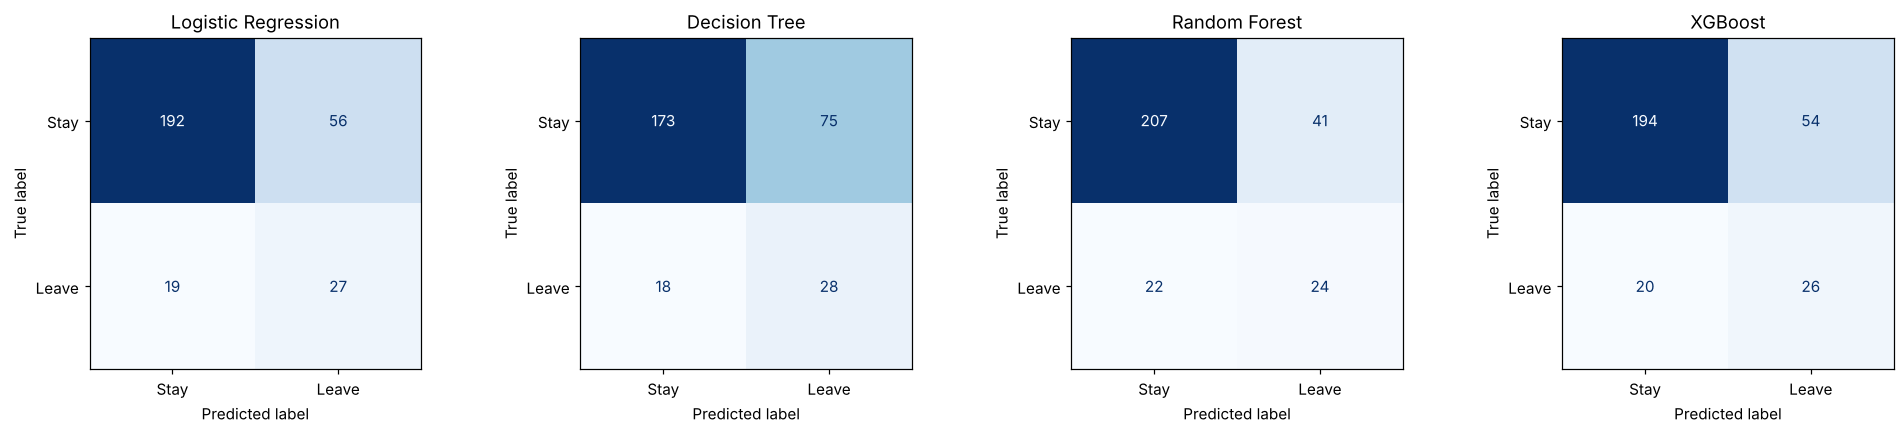

In [1]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
for n, p in tuned.items():
    fpr, tpr, _ = roc_curve(y_test, p.predict_proba(X_test)[:, 1]); ax[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, p.predict_proba(X_test)[:,1]):.3f})")
ax[0].plot([0, 1], [0, 1], "k--"); ax[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC curves (tuned, test set)"); ax[0].legend(fontsize=8)
x = np.arange(len(base_df)); w = .38
ax[1].bar(x - w/2, base_df["ROC-AUC"], w, label="Baseline"); ax[1].bar(x + w/2, tuned_df["ROC-AUC"], w, label="Tuned")
ax[1].set_xticks(x); ax[1].set_xticklabels([i.split(" (")[0] for i in base_df.index], rotation=15); ax[1].set_ylim(.5, 1); ax[1].set_title("ROC-AUC before vs after tuning"); ax[1].legend()
savefig("03_roc_and_tuning.png")

fig, axs = plt.subplots(1, 4, figsize=(18, 4))
for a, (n, p) in zip(axs, tuned.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, p.predict(X_test)), display_labels=["Stay", "Leave"]).plot(ax=a, colorbar=False, cmap="Blues"); a.set_title(n.split(" (")[0])
savefig("04_confusion_matrices.png")

## 8. Feature importance

Best model by test ROC-AUC: Logistic Regression


MonthlyIncome           0.1543
OverTime                0.0566
JobSatisfaction         0.0198
YearsWithCurrManager    0.0185
Age                     0.0163
StockOptionLevel        0.0120
MaritalStatus           0.0084
NumCompaniesWorked      0.0039
BusinessTravel          0.0038
DistanceFromHome        0.0034
dtype: float64

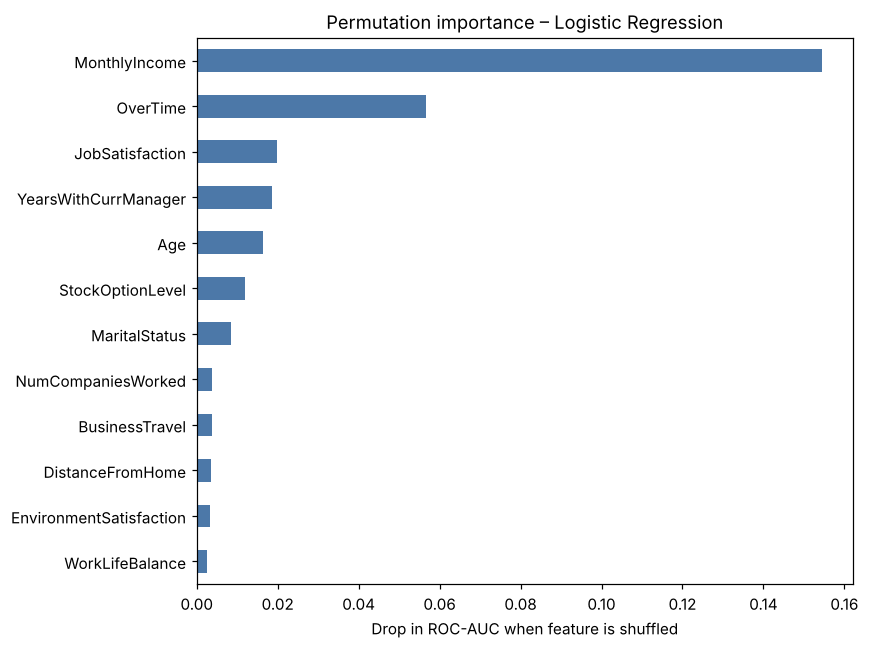

In [1]:
best_name = tuned_df["ROC-AUC"].idxmax(); print("Best model by test ROC-AUC:", best_name)
# permutation importance on RAW columns (interpretable for HR), computed on the test set
pi = permutation_importance(tuned[best_name], X_test, y_test, scoring="roc_auc", n_repeats=15, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6)); imp.head(12)[::-1].plot.barh(color="#4c78a8"); plt.xlabel("Drop in ROC-AUC when feature is shuffled")
plt.title(f"Permutation importance – {best_name.split(' (')[0]}"); savefig("05_permutation_importance.png")
imp.head(10).round(4)

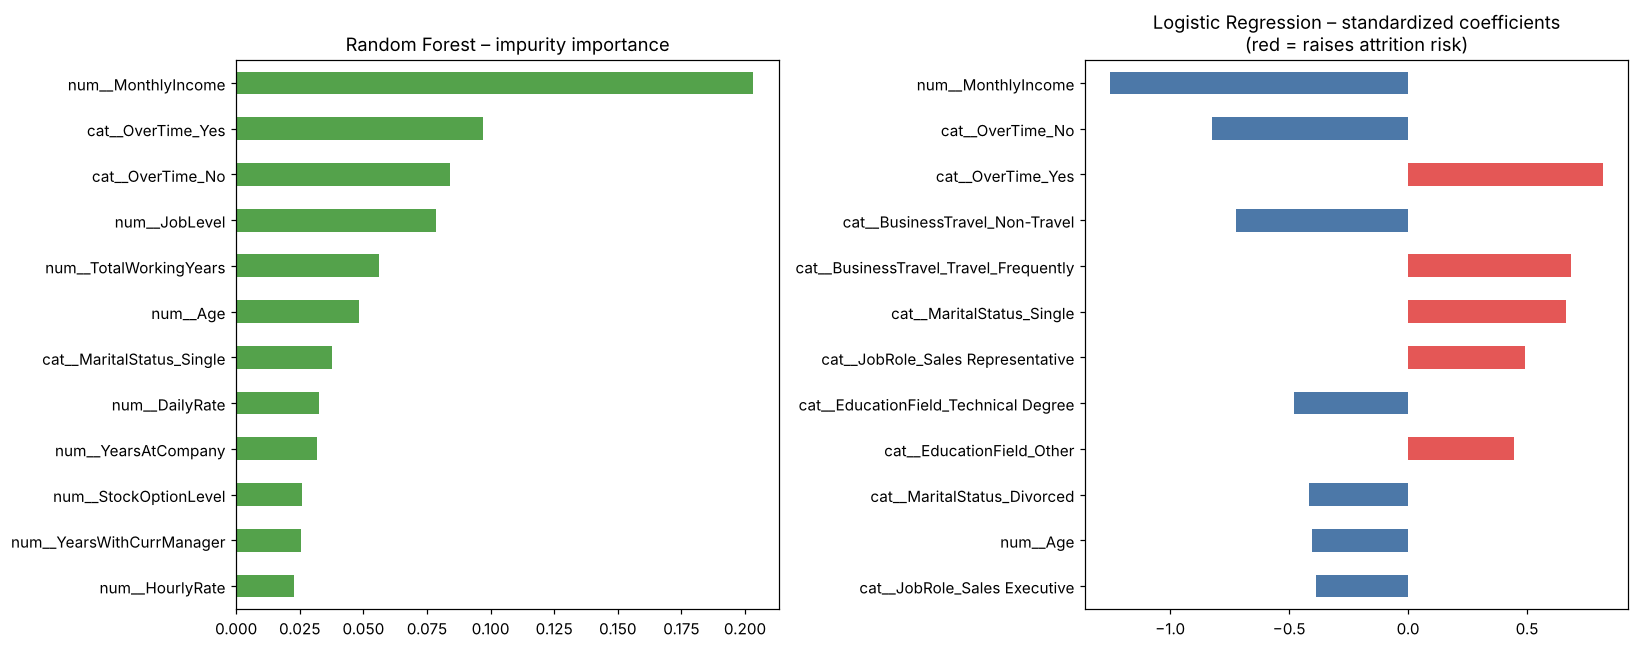

In [1]:
# Tree-based importance (Random Forest) and Logistic Regression odds ratios
rf = tuned["Random Forest"]; names = rf.named_steps["pre"].get_feature_names_out()
rf_imp = pd.Series(rf.named_steps["clf"].feature_importances_, index=names).sort_values(ascending=False)
lr = tuned["Logistic Regression"]; coefs = pd.Series(lr.named_steps["clf"].coef_[0], index=lr.named_steps["pre"].get_feature_names_out())
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index)[:12][::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
rf_imp.head(12)[::-1].plot.barh(ax=ax[0], color="#54a24b"); ax[0].set_title("Random Forest – impurity importance")
top.plot.barh(ax=ax[1], color=np.where(top > 0, "#e45756", "#4c78a8")); ax[1].set_title("Logistic Regression – standardized coefficients\n(red = raises attrition risk)")
savefig("06_rf_and_lr_importance.png")

## 9. Optional regression task – predict **JobSatisfaction** (1–4)
Models: Linear Regression vs Random Forest Regressor, evaluated with MAE, RMSE and R² on a held-out 20 %.

In [1]:
yr = df["JobSatisfaction"]; Xr = df.drop(columns=DROP + ["Attrition", "JobSatisfaction"])
cat_r = Xr.select_dtypes("object").columns.tolist(); num_r = [c for c in Xr.columns if c not in cat_r]
Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(Xr, yr, test_size=0.2, random_state=SEED)
pre_r = lambda: ColumnTransformer([("num", StandardScaler(), num_r), ("cat", OneHotEncoder(handle_unknown="ignore"), cat_r)])
reg = {"Linear Regression": LinearRegression(),
       "Random Forest Regressor": RandomForestRegressor(n_estimators=300, max_depth=8, min_samples_leaf=5, random_state=SEED, n_jobs=-1)}
rows = {}
for n, m in reg.items():
    p = Pipeline([("pre", pre_r()), ("m", m)]).fit(Xr_tr, yr_tr); pr = p.predict(Xr_te)
    rows[n] = {"MAE": mean_absolute_error(yr_te, pr), "RMSE": mean_squared_error(yr_te, pr) ** .5, "R2": r2_score(yr_te, pr)}
base_rmse = (((yr_te - yr_tr.mean()) ** 2).mean()) ** .5
reg_df = pd.DataFrame(rows).T.round(3); reg_df.loc["Baseline (predict mean)"] = [mean_absolute_error(yr_te, np.full(len(yr_te), yr_tr.mean())), base_rmse, 0.0]
reg_df.round(3)

,MAE,RMSE,R2
Linear Regression,0.939,1.104,-0.072
Random Forest Regressor,0.936,1.096,-0.057
Baseline (predict mean),0.920,1.066,0.000


## 10. Save results (used by the report generator)

In [1]:
base_df.to_csv(RES / "baseline_metrics.csv"); tuned_df.to_csv(RES / "tuned_metrics.csv"); cv_df.to_csv(RES / "cv_metrics.csv")
reg_df.round(3).to_csv(RES / "regression_metrics.csv"); imp.to_csv(RES / "permutation_importance.csv", header=["importance"])
overtime = (df.assign(A=df.Attrition.eq("Yes")).groupby("OverTime").A.mean() * 100).round(1).to_dict()
json.dump({"data_source": DATA_SOURCE, "n_rows": int(len(df)), "n_features": int(X.shape[1]), "attrition_rate": float(rate),
           "xgboost_real": XGB_REAL, "best_model": best_name, "best_params": best_params,
           "overtime_attrition_pct": overtime,
           "top_features": imp.head(8).round(4).to_dict(),
           "top_lr_positive": coefs.sort_values(ascending=False).head(5).round(3).to_dict(),
           "top_lr_negative": coefs.sort_values().head(5).round(3).to_dict()},
          open(RES / "summary.json", "w"), indent=2, default=str)
print("saved ->", RES)

saved -> ../results


## 11. Conclusions
* All models were tuned with 5-fold CV and compared on a held-out test set using Accuracy, Precision, Recall, F1 and ROC-AUC.
* Because only ~16 % of employees leave, **accuracy alone is misleading** – Recall, F1 and ROC-AUC are the metrics that matter for HR.
* The feature-importance sections show which factors (overtime, income, tenure, travel, satisfaction…) drive attrition risk; see the *Business Interpretation Report*.
* The regression task shows that satisfaction is only weakly predictable from HR records – survey data would be needed.